In [1]:

import numpy as np
from itertools import combinations
import matplotlib.pyplot as plt
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import QAOAAnsatz
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from scipy.optimize import minimize
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.translators import from_docplex_mp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
%matplotlib inline

In [2]:
# inputs
rng = np.random.default_rng(2026)
n, K, q = 6, 3, 0.5               # stocks, pick exactly K, risk aversion
mu = rng.uniform(0.05, 0.25, n)   # expected returns
A = rng.normal(0, 0.1, (n, n))
sigma = A @ A.T                   # covariance (risk)
lam = 0.5 # from earlier example

In [3]:
# create the cost function per state
def getCost(x):
    return q * x @ sigma @ x - mu @ x + lam * (x.sum() - K) ** 2

In [4]:
A

array([[-0.03119493,  0.03038354, -0.02676603, -0.02259089,  0.07200678,
         0.05147052],
       [-0.00641279, -0.00854766,  0.01609163, -0.06140184, -0.04037503,
         0.05482602],
       [-0.01304828, -0.13744262, -0.04772787,  0.06566216, -0.02322828,
        -0.01487328],
       [ 0.06418366,  0.18246103, -0.07131887,  0.13482068, -0.12300128,
         0.01749776],
       [-0.11695295,  0.13514582,  0.0833923 ,  0.11377168, -0.08855332,
         0.0684555 ],
       [-0.05190133, -0.04573853,  0.05065371,  0.08767182,  0.02044202,
        -0.06279871]])

In [5]:
mu

array([0.08578696, 0.17798263, 0.14345368, 0.12410011, 0.12098347,
       0.20810365])

In [6]:
# create 20 states (all valid portfolios) and find the brute-force optimum
stocks_lists = []
for stocks in combinations(range(n), K):
    x = np.zeros(n, dtype=int)
    x[list(stocks)] = 1
    stocks_lists.append(x)

best_x = min(stocks_lists, key=getCost)
print("brute-force best:", best_x, "cost:", round(getCost(best_x), 4))

brute-force best: [0 1 1 0 0 1] cost: -0.503


The quantum based circuit and optimisation has four key stages:

1. Creating the necessary inputs - the covariance matrices, returns per stock, etc. All the above information is provided in cell 2.

2. Create Pauli matrices. These transform the above math into quantum problems. Qiskit's SparsePauliOp is used to store these efficiently.

3. Create the circuit and run the hybrid optimisation loop. this is done in phases:

a. Create a new instance of QAOAAnsatz class (Ansatz object) and pass the cost matrices (Hamiltonian) computed in step 1.

b. Define the execution env - local or IBM Hardware (configure with API keys).

c. Run a hybrid optimisation loop - using scikit and qiskit. This is a tyuning phase where the optimal values for a specific class are defined based on iterative tuning by scikit's minimizer (like COBYLA) and qiskit estimator (computes the Hamiltonian).

d. The above generated Hamiltonian is then passed to scikit's minimizer and the key params are tuned to minimize this.

4. Once the best params are inferred, the values are substituted in the circuit designed from Step 3. The run is performed over multiple iterations (bootstraps or 'shots'), and most frequent bitstrings are recorded.

5. Using a combination of bitstrings and the original formulation (step 1), compute the results and grade their performance.

For all binary problems, the quantum mapping starts with the same formulation : **Quadratic Unconstrained Binary Optimization (QUBO) + Ising Model (The Quantum Mapping)**. Jordan-Wigner transformation or the Bravyi-Kitaev transformation are used for continuous variable transformations.

In [7]:
linear_dict = {}
quadratic_dict = {}

# 1. Build the Linear Dictionary
for i in range(n):
    var_name = f"x_{i}"
    
    # Linear = (q * Individual Risk) - Return + Penalty_linear_term
    linear_value = (q * sigma[i][i]) - mu[i] + lam * (1 - 2 * K)
    linear_dict[var_name] = float(linear_value)

# 2. Build the Quadratic Dictionary
for i in range(n):
    for j in range(i + 1, n): # i+1 to n avoids self-loops and duplicate pairs
        pair = (f"x_{i}", f"x_{j}")
        
        # Quadratic = (2 * q * Covariance) + Penalty_quadratic_term
        # Multiply risk by 2 because the matrix is symmetric and we only loop the upper triangle
        quad_value = (2 * q * sigma[i][j]) + (2 * lam)
        quadratic_dict[pair] = float(quad_value)

# 3. Calculate Constant
constant_val = float(lam * (K ** 2))

# 4. Initialize the Model and apply the dictionaries
mod = QuadraticProgram("Portfolio_Optimization")

# Add the binary variables to the model
for i in range(n):
    mod.binary_var(name=f"x_{i}")

# Add the objective function using the dictionaries
mod.minimize(
    constant=constant_val,
    linear=linear_dict,
    quadratic=quadratic_dict
)

print(mod.prettyprint())

Problem name: Portfolio_Optimization

Minimize
  1.0008113994408356*x_0*x_1 + 0.9935870376333713*x_0*x_2
  + 0.9944485034328278*x_0*x_3 + 1.0000992646508156*x_0*x_4
  + 0.9951326594250233*x_0*x_5 + 0.9965810909103168*x_1*x_2
  + 0.99452842689045*x_1*x_3 + 1.00127942808483*x_1*x_4
  + 0.9918873294002502*x_1*x_5 + 0.9889379656239696*x_2*x_3
  + 0.9874803799882487*x_2*x_4 + 1.0107619637008627*x_2*x_5
  + 1.0386336963720304*x_3*x_4 + 0.992917460225041*x_3*x_5
  + 1.0079782158331936*x_4*x_5 - 2.580308341338772*x_0 - 2.6735929592025283*x_1
  - 2.6302481966512388*x_2 - 2.586045078864128*x_3 - 2.588799216268185*x_4
  - 2.698403918422438*x_5 + 4.5

Subject to
  No constraints

  Binary variables (6)
    x_0 x_1 x_2 x_3 x_4 x_5



In [8]:
pauliop, offset = mod.to_ising() # returns two

In [9]:
pauliop

SparsePauliOp(['IIIIIZ', 'IIIIZI', 'IIIZII', 'IIZIII', 'IZIIII', 'ZIIIII', 'IIIIZZ', 'IIIZIZ', 'IIZIIZ', 'IZIIIZ', 'ZIIIIZ', 'IIIZZI', 'IIZIZI', 'IZIIZI', 'ZIIIZI', 'IIZZII', 'IZIZII', 'ZIIZII', 'IZZIII', 'ZIZIII', 'ZZIIII'],
              coeffs=[0.04413445+0.j, 0.09052456+0.j, 0.07078699+0.j, 0.04065603+0.j,
 0.03553186+0.j, 0.09953255+0.j, 0.25020285+0.j, 0.24839676+0.j,
 0.24861213+0.j, 0.25002482+0.j, 0.24878316+0.j, 0.24914527+0.j,
 0.24863211+0.j, 0.25031986+0.j, 0.24797183+0.j, 0.24723449+0.j,
 0.24687009+0.j, 0.25269049+0.j, 0.25965842+0.j, 0.24822937+0.j,
 0.25199455+0.j])

In [10]:
offset

np.float64(0.3700673500293717)

In [11]:
print(mod.prettyprint())

Problem name: Portfolio_Optimization

Minimize
  1.0008113994408356*x_0*x_1 + 0.9935870376333713*x_0*x_2
  + 0.9944485034328278*x_0*x_3 + 1.0000992646508156*x_0*x_4
  + 0.9951326594250233*x_0*x_5 + 0.9965810909103168*x_1*x_2
  + 0.99452842689045*x_1*x_3 + 1.00127942808483*x_1*x_4
  + 0.9918873294002502*x_1*x_5 + 0.9889379656239696*x_2*x_3
  + 0.9874803799882487*x_2*x_4 + 1.0107619637008627*x_2*x_5
  + 1.0386336963720304*x_3*x_4 + 0.992917460225041*x_3*x_5
  + 1.0079782158331936*x_4*x_5 - 2.580308341338772*x_0 - 2.6735929592025283*x_1
  - 2.6302481966512388*x_2 - 2.586045078864128*x_3 - 2.588799216268185*x_4
  - 2.698403918422438*x_5 + 4.5

Subject to
  No constraints

  Binary variables (6)
    x_0 x_1 x_2 x_3 x_4 x_5



### Creating the circuit and using IBM hardware

In [12]:
with open('/mnt/g/quantum_qiskit_hackathon/ibm_key.txt', 'r') as f:
  api_key = f.readline()

In [13]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(
    channel="ibm_quantum_platform", # optional
    token=api_key,
    instance="crn:v1:bluemix:public:quantum-computing:us-east:a/65f9f33d235f4862a3082307230b71c8:790aac10-9e06-4821-9125-c79043f61fe0::" # recommended
    )

qiskit_runtime_service._discover_account:WARNING:2026-10-14 01:01:46,932: Loading account with the given token. A saved account will not be used.


In [14]:
# backend = service.least_busy(
#     operational=True, simulator=True, min_num_qubits=127
# )
# print(backend)

# # Create pass manager for transpilation. Level 3 is the most aggressive
# # preset: slower to transpile, but produces shorter circuits that are
# # more robust to hardware noise.
# pm = generate_preset_pass_manager(optimization_level=3, backend=backend)

# candidate_circuit = pm.run(circuit)
# candidate_circuit.draw("mpl", fold=False, idle_wires=False)

In [15]:
# QiskitRuntimeService.save_account(
#   # For `token`, use the 44-character API_KEY you created 
#   # and saved from the IBM Quantum Platform Home dashboard:
#   token=api_key, 
#   name="SreeramPeela", # Optional
#   instance="crn:v1:bluemix:public:quantum-computing:us-east:a/65f9f33d235f4862a3082307230b71c8:790aac10-9e06-4821-9125-c79043f61fe0::", # Optional
#   set_as_default=True, # Optional
#   overwrite=False, # Optional
# )

In [16]:
# Map the Cost Hamiltonian to the physical qubits chosen during transpilation
# isa_observable = pauliop.apply_layout(candidate_circuit.layout)

In [17]:
# # 1. Initialize tracking list
# objective_func_vals = []

# def cost_function(angles):
#     job = estimator.run([(candidate_circuit, isa_observable, angles)])
#     result = job.result()[0]
    
#     # Extract expectation value and cast to float
#     energy = float(result.data.evs)
    
#     # Append each evaluated cost
#     objective_func_vals.append(energy)
#     return energy

Starting optimization...
  start 0: <C> = 0.1367
  start 1: <C> = 0.0131
  start 2: <C> = -0.3426
  start 3: <C> = -0.2020
  start 4: <C> = -0.2164
  start 5: <C> = 0.2757
  start 6: <C> = -0.2573
  start 7: <C> = -0.3115
Optimization finished! Best angles: [1.32691354 1.45731576 0.77030485 2.77016865]
Best <C> = -0.3426


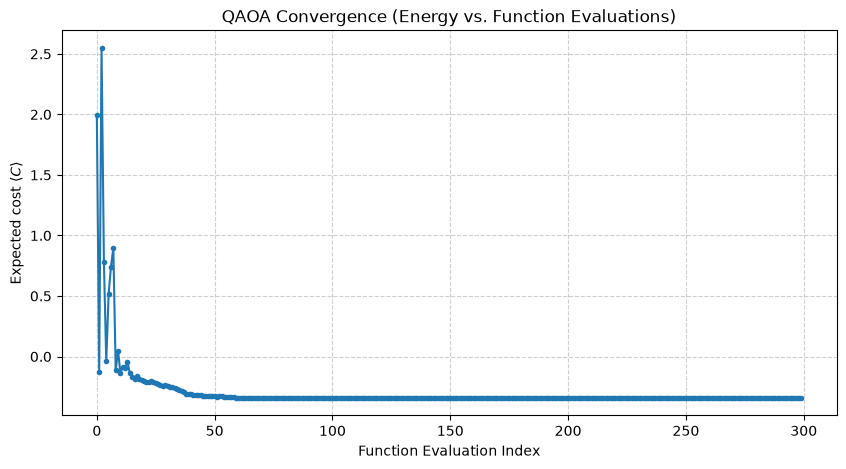

In [18]:
# 1. Build the circuit and transpile it ONCE, before the optimizer loop
#    (much faster per evaluation, and avoids the SciPy SparseEfficiencyWarnings)
pm = generate_preset_pass_manager(optimization_level=1, basis_gates=["rz", "sx", "x", "cx"])
estimator_circuit = pm.run(QAOAAnsatz(cost_operator=pauliop, reps=2))
local_estimator = StatevectorEstimator()

# Initialize the tracking list
objective_func_vals = []

# 2. Cost function: expected energy <H> for the given angles
def cost_function(angles):
    job = local_estimator.run([(estimator_circuit, pauliop, angles)])
    energy = float(job.result()[0].data.evs)
    objective_func_vals.append(energy)
    return energy

# 3. Multi-start optimization: a single random start can get stuck in a poor
#    local minimum, so run several and keep the one with the lowest energy
num_params = estimator_circuit.num_parameters
angle_rng = np.random.default_rng(42)
optimization_result, best_history = None, []

print("Starting optimization...")
for start in range(8):
    objective_func_vals.clear()
    initial_angles = angle_rng.uniform(0, np.pi, num_params)
    trial = minimize(cost_function, initial_angles, method="COBYLA", options={"maxiter": 300})
    print(f"  start {start}: <C> = {trial.fun + offset:.4f}")
    if optimization_result is None or trial.fun < optimization_result.fun:
        optimization_result, best_history = trial, list(objective_func_vals)
objective_func_vals = best_history  # convergence curve of the best start

print(f"Optimization finished! Best angles: {optimization_result.x}")
print(f"Best <C> = {optimization_result.fun + offset:.4f}")

# 4. Plot the convergence curve of the best start (offset added, so this is <C>)
plt.figure(figsize=(10, 5))
plt.plot(np.array(objective_func_vals) + offset, marker="o", markersize=3, linestyle="-", color="tab:blue")
plt.title("QAOA Convergence (Energy vs. Function Evaluations)")
plt.xlabel("Function Evaluation Index")
plt.ylabel("Expected cost $\\langle C \\rangle$")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

In [19]:
from qiskit.primitives import StatevectorSampler

# 1. Create a measured copy of the circuit for the Sampler
sampler_circuit = estimator_circuit.copy()
sampler_circuit.measure_all()

# 2. Bind the optimal angles found by SciPy
bound_circuit = sampler_circuit.assign_parameters(optimization_result.x)

# 3. Sample the final portfolios locally
local_sampler = StatevectorSampler(seed = 42)
job = local_sampler.run([bound_circuit], shots=4096)
result = job.result()[0]

# Print the measured bitstrings
counts = result.data.meas.get_counts()
print(counts)

{'101100': 209, '011010': 197, '110010': 209, '101010': 183, '001011': 203, '111000': 189, '001101': 199, '011100': 194, '011001': 158, '110100': 200, '101001': 187, '110001': 194, '010011': 190, '100101': 198, '100110': 199, '001110': 216, '000111': 194, '010110': 213, '010101': 190, '001111': 4, '100011': 210, '010010': 11, '100001': 3, '110011': 2, '011110': 3, '001001': 4, '101000': 9, '110000': 8, '110111': 4, '111101': 2, '111111': 11, '001010': 3, '101011': 3, '111011': 2, '100111': 5, '100000': 2, '101110': 5, '010111': 4, '111110': 4, '101101': 5, '111010': 6, '001100': 3, '000010': 1, '000001': 4, '011111': 2, '000110': 4, '111001': 5, '101111': 2, '000011': 2, '100010': 2, '000000': 4, '111100': 3, '001000': 1, '110101': 3, '010001': 3, '011011': 6, '011000': 3, '110110': 7, '010100': 4, '010000': 2, '000100': 2, '100100': 1}


In [20]:
print(counts)

{'101100': 209, '011010': 197, '110010': 209, '101010': 183, '001011': 203, '111000': 189, '001101': 199, '011100': 194, '011001': 158, '110100': 200, '101001': 187, '110001': 194, '010011': 190, '100101': 198, '100110': 199, '001110': 216, '000111': 194, '010110': 213, '010101': 190, '001111': 4, '100011': 210, '010010': 11, '100001': 3, '110011': 2, '011110': 3, '001001': 4, '101000': 9, '110000': 8, '110111': 4, '111101': 2, '111111': 11, '001010': 3, '101011': 3, '111011': 2, '100111': 5, '100000': 2, '101110': 5, '010111': 4, '111110': 4, '101101': 5, '111010': 6, '001100': 3, '000010': 1, '000001': 4, '011111': 2, '000110': 4, '111001': 5, '101111': 2, '000011': 2, '100010': 2, '000000': 4, '111100': 3, '001000': 1, '110101': 3, '010001': 3, '011011': 6, '011000': 3, '110110': 7, '010100': 4, '010000': 2, '000100': 2, '100100': 1}


In [21]:
print(result)

SamplerPubResult(data=DataBin(meas=BitArray(<shape=(), num_shots=4096, num_bits=6>)), metadata={'shots': 4096, 'circuit_metadata': {}})


In [22]:
valid_counts = {k: v for k, v in counts.items() if k.count('1') == K}

# Sort them by most frequently measured
sorted_valid_counts = dict(sorted(valid_counts.items(), key=lambda item: item[1], reverse=True))

print(sorted_valid_counts)

# Sanity checks: random guessing gives ~31.3% valid (20/64) and ~1.6% optimum (1/64).
# If you are near those numbers, the optimization failed.
shots = sum(counts.values())
best_key = "".join(map(str, best_x))[::-1]  # brute-force optimum written as a Qiskit key
print(f"valid fraction: {sum(valid_counts.values()) / shots:.1%}")
print(f"P(optimum):     {counts.get(best_key, 0) / shots:.1%}")

{'001110': 216, '010110': 213, '100011': 210, '101100': 209, '110010': 209, '001011': 203, '110100': 200, '001101': 199, '100110': 199, '100101': 198, '011010': 197, '011100': 194, '110001': 194, '000111': 194, '010011': 190, '010101': 190, '111000': 189, '101001': 187, '101010': 183, '011001': 158}
valid fraction: 96.0%
P(optimum):     4.9%


In [23]:
len(sorted_valid_counts.keys())

20

In [24]:
# Pick the sampled valid portfolio with the LOWEST COST, not the most frequent one:
# counts among valid portfolios differ by shot noise, so frequency alone is unreliable.
# Qiskit keys are little-endian (qubit 0 is the rightmost character), so reverse to get x_0..x_5.
def key_to_x(key):
    return np.array([int(b) for b in key[::-1]])

qaoa_key = min(valid_counts, key=lambda k: getCost(key_to_x(k)))
qaoa_x = key_to_x(qaoa_key)

print("QAOA best portfolio:", qaoa_x, "cost:", round(getCost(qaoa_x), 4),
      f"(sampled {valid_counts[qaoa_key]} times)")
print("matches brute force:", np.array_equal(qaoa_x, best_x))

QAOA best portfolio: [0 1 1 0 0 1] cost: -0.503 (sampled 199 times)
matches brute force: True
